In [18]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from copy import deepcopy
import pandas as pd

def draw_highlighted_atoms(mol, atom_ids):
    
    local_mol = deepcopy(mol)  # Create a deep copy of the molecule to avoid modifying the original
    for i, atom in enumerate(local_mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(local_mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

In [19]:
#smarts_train_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_train.csv"
#smarts_train_df = pd.read_csv(smarts_train_fp)

#smarts_val_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_val.csv"
#smarts_val_df = pd.read_csv(smarts_val_fp)

#smarts_test_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_test.csv"
#smarts_test_df = pd.read_csv(smarts_test_fp)


smarts_train_fp = "../../data/smarts/debug_tiny/smarts_train.csv"
smarts_train_df = pd.read_csv(smarts_train_fp)

smarts_val_fp = "../../data/smarts/debug_tiny/smarts_val.csv"
smarts_val_df = pd.read_csv(smarts_val_fp)

smarts_test_fp = "../../data/smarts/debug_tiny/smarts_test.csv"
smarts_test_df = pd.read_csv(smarts_test_fp)

In [20]:
import pandas as pd

def get_smarts_df_stats(smarts_dict):
    """
    Generate statistics from a dictionary of {name: DataFrame}, 
    where each DataFrame contains 'prec_type', 'formula', and 'smiles' columns.

    Returns a summary DataFrame with:
    - Total and unique counts of formulas and SMILES per prec_type per dataset
    - Count of overlapping unique formulas and SMILES across prec_types in each dataset
    """
    summary_rows = []

    for name, df in smarts_dict.items():
        grouped = df.groupby('prec_type')
        formula_counts = grouped['formula'].count()
        smiles_counts = grouped['smiles'].count()
        unique_formulas = grouped['formula'].nunique()
        unique_smiles = grouped['smiles'].nunique()

        for prec_type in grouped.groups.keys():
            summary_rows.append({
                'dataset': name,
                'prec_type': prec_type,
                'formula_count': formula_counts[prec_type],
                'smiles_count': smiles_counts[prec_type],
                'unique_formulas': unique_formulas[prec_type],
                'unique_smiles': unique_smiles[prec_type]
            })

        # Overlap calculations using unique formulas/SMILES only
        formula_sets = grouped['formula'].apply(lambda x: set(x.unique()))
        smiles_sets = grouped['smiles'].apply(lambda x: set(x.unique()))

        overlapping_formulas = set.intersection(*formula_sets) if len(formula_sets) > 1 else set()
        overlapping_smiles = set.intersection(*smiles_sets) if len(smiles_sets) > 1 else set()

        summary_rows.append({
            'dataset': name,
            'prec_type': 'OVERLAP',
            'formula_count': len(overlapping_formulas),
            'smiles_count': len(overlapping_smiles),
            'unique_formulas': len(overlapping_formulas),
            'unique_smiles': len(overlapping_smiles)
        })

    return pd.DataFrame(summary_rows)


smarts_dict = {
    'train': smarts_train_df,
    'val': smarts_val_df,
    'test': smarts_test_df
}
get_smarts_df_stats(smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,7216,7216,1317,6305
1,train,[M+Na]+,9207,9207,822,8907
2,train,[M-H]-,8757,8757,1003,6956
3,train,OVERLAP,103,861,103,861
4,val,[M+H]+,6417,6417,1216,3996
5,val,[M+Na]+,2757,2757,561,2244
6,val,[M-H]-,8977,8977,1484,5005
7,val,OVERLAP,311,1209,311,1209
8,test,[M+H]+,4004,4004,975,3006
9,test,[M+Na]+,952,952,210,625


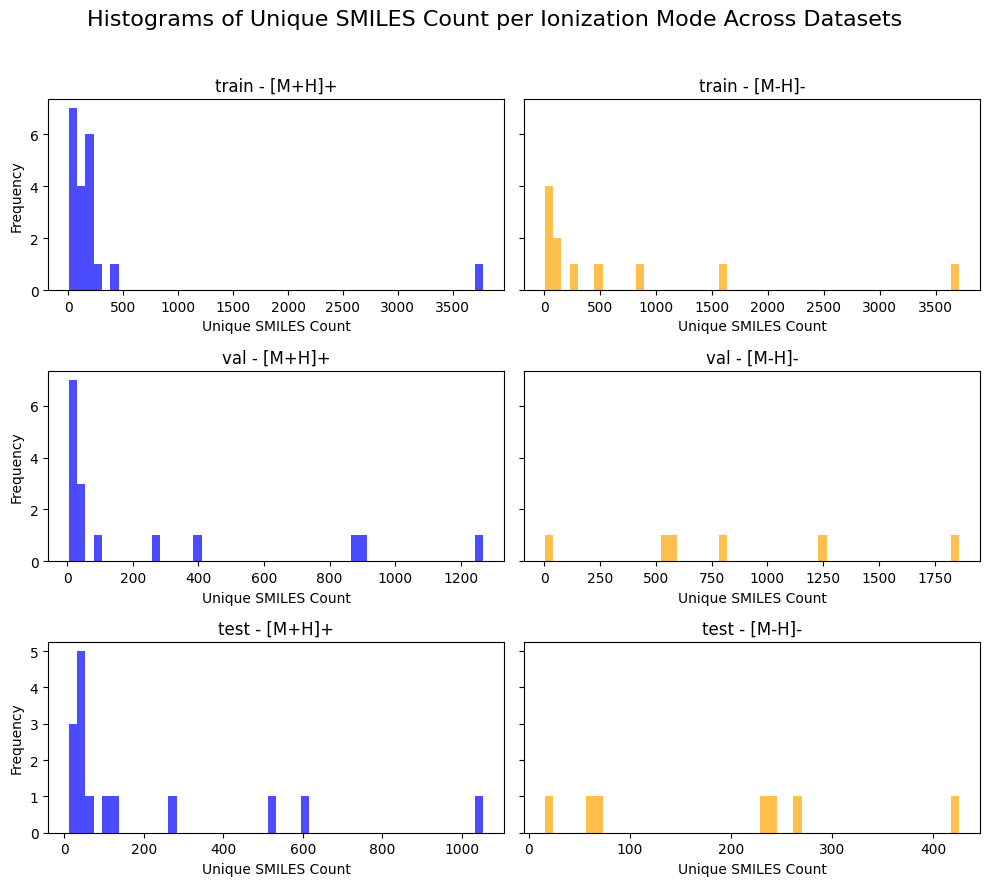

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_unique_smiles_histograms(smarts_dict, smiles_col='smiles', mol_col='mol_smiles', prec_col='prec_type', bins=50):
    """
    Plots histograms of unique SMILES count per mol_smiles for each ionization mode ([M+H]+ and [M-H]-),
    across multiple datasets provided as a dictionary.

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing precursor type, SMILES, and molecule columns.
        smiles_col (str): Column name for SMILES.
        mol_col (str): Column name for molecule identifier (e.g., canonical SMILES).
        prec_col (str): Column name for precursor type (e.g., [M+H]+ or [M-H]-).
        bins (int): Number of histogram bins.
    """
    n = len(smarts_dict)
    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 3 * n), sharey='row')

    if n == 1:
        axes = [axes]  # ensure iterable even when 1 dataset

    for idx, (name, df) in enumerate(smarts_dict.items()):
        # Count unique SMILES per mol_smiles within each prec_type
        unique_counts = (
            df.groupby([prec_col, mol_col])[smiles_col]
            .nunique()
            .reset_index()
            .rename(columns={smiles_col: 'unique_smiles_count'})
        )

        mh_plus_data = unique_counts[unique_counts[prec_col] == '[M+H]+']
        mh_minus_data = unique_counts[unique_counts[prec_col] == '[M-H]-']

        ax1, ax2 = axes[idx]

        # [M+H]+ Histogram
        ax1.hist(mh_plus_data['unique_smiles_count'], bins=bins, color='blue', alpha=0.7)
        ax1.set_title(f'{name} - [M+H]+')
        ax1.set_xlabel('Unique SMILES Count')
        ax1.set_ylabel('Frequency')

        # [M-H]- Histogram
        ax2.hist(mh_minus_data['unique_smiles_count'], bins=bins, color='orange', alpha=0.7)
        ax2.set_title(f'{name} - [M-H]-')
        ax2.set_xlabel('Unique SMILES Count')

    plt.suptitle('Histograms of Unique SMILES Count per Ionization Mode Across Datasets', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_unique_smiles_histograms(smarts_dict)

In [22]:
import pandas as pd
from itertools import combinations

def get_unique_smiles_overlap_by_precursor(smarts_dict, smiles_col='smiles', prec_col='prec_type'):
    """
    Computes pairwise SMILES overlaps across datasets, grouped by precursor type (e.g., [M+H]+, [M-H]-).

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing a SMILES and prec_type column.
        smiles_col (str): Column name for SMILES (default: 'smiles').
        prec_col (str): Column name for precursor type (default: 'prec_type').

    Returns:
        overlap_df (pd.DataFrame): DataFrame with per-precursor-type pairwise SMILES overlap stats:
            - dataset_1, dataset_2
            - overlap_count
            - overlap_%_of_dataset_1
            - overlap_%_of_dataset_2
            - prec_type
        global_overlap_dict (dict): {prec_type: set of SMILES shared across all datasets for that type}
    """
    all_prec_types = set().union(*[set(df[prec_col].dropna().unique()) for df in smarts_dict.values()])
    overlap_rows = []
    global_overlap_dict = {}

    for prec in all_prec_types:
        # Extract SMILES sets for this precursor from each dataset
        smiles_sets = {
            name: set(df[df[prec_col] == prec][smiles_col].unique())
            for name, df in smarts_dict.items()
        }

        # Remove empty sets (datasets without this precursor)
        smiles_sets = {k: v for k, v in smiles_sets.items() if v}

        # Skip if fewer than 2 datasets contain this precursor
        if len(smiles_sets) < 2:
            continue

        # Pairwise comparisons
        for (name1, set1), (name2, set2) in combinations(smiles_sets.items(), 2):
            intersect = set1 & set2
            overlap_count = len(intersect)
            percent_in_1 = 100 * overlap_count / len(set1) if set1 else 0
            percent_in_2 = 100 * overlap_count / len(set2) if set2 else 0

            overlap_rows.append({
                'prec_type': prec,
                'dataset_1': name1,
                'dataset_2': name2,
                'overlap_count': overlap_count,
                'overlap_%_of_dataset_1': round(percent_in_1, 2),
                'overlap_%_of_dataset_2': round(percent_in_2, 2),
            })

        # Global intersection for this precursor
        global_overlap_dict[prec] = set.intersection(*smiles_sets.values())

    overlap_df = pd.DataFrame(overlap_rows)
    return overlap_df, global_overlap_dict

overlap_df, global_smiles = get_unique_smiles_overlap_by_precursor(smarts_dict)
overlap_df


,prec_type,dataset_1,dataset_2,overlap_count,overlap_%_of_dataset_1,overlap_%_of_dataset_2
0,[M-H]-,train,val,32,0.46,0.64
1,[M-H]-,train,test,9,0.13,0.69
2,[M-H]-,val,test,13,0.26,0.99
3,[M+Na]+,train,val,1,0.01,0.04
4,[M+Na]+,train,test,4,0.04,0.64
5,[M+Na]+,val,test,0,0.00,0.00
6,[M+H]+,train,val,83,1.32,2.08
7,[M+H]+,train,test,55,0.87,1.83
8,[M+H]+,val,test,38,0.95,1.26


In [23]:
# Concatenate SMILES from all datasets
all_smiles = pd.concat([df['smiles'] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES
smiles_frequency = all_smiles.value_counts()

# Display the result
smiles_frequency

smiles
*C(*)C(*)C(*)O                                            32
*C(C)=CCc1c(O)c(CC=C(*)C)c2[nH]c(c(*)O)c(c*)c(=O)c2c1O    28
*C(C)=CCc1c(O)c(CC=C(*)C)c2[nH]c(c(O)c*)c(*)c(=O)c2c1O    28
*C(C)=CCc1c(O)c(CC=C(*)C)c2[nH]c(c(*)O)c(*)c(=O)c2c1O     28
*c(c*)cc*                                                 24
                                                          ..
*c1cc(Br)cc(Br)c1O                                         1
*CC(*)(*)C1CCC2C(*)(CCC3c4ccoc4CCC32C)C1                   1
*CCC1CC(*)(CCC2c3ccoc3CCC2(*)C)CC1(O)C*                    1
*CCC1CC(*)(CCC2c3ccoc3CCC2(*)C)CC1(*)O                     1
*CCC1CC(*)(CCC2c3ccoc3CCC2(*)C)CC1(*)CO                    1
Name: count, Length: 28302, dtype: int64

In [24]:
all_smarts = pd.concat([df[['smarts']] for df in smarts_dict.values()])
smart_frequency = all_smarts.value_counts()
smart_frequency

smarts                                                                                                                                                                                                                                     
[#6:1](-[#6:2]-[#6:3]-[#6:4]-[!#1])-[!#1]                                                                                                                                                                                                      24
[#6:1](-[#6:2](-[#8:3])-[#6:4](-[!#1])-[!#1])(-[!#1])-[!#1]                                                                                                                                                                                    16
[#6:1](-[#6:2](-[#6:3](-[#8:4])-[!#1])-[!#1])(-[!#1])-[!#1]                                                                                                                                                                                    16
[#6:1](-[#8:2])(-[#6:3](-[#8:4])-[!#1]

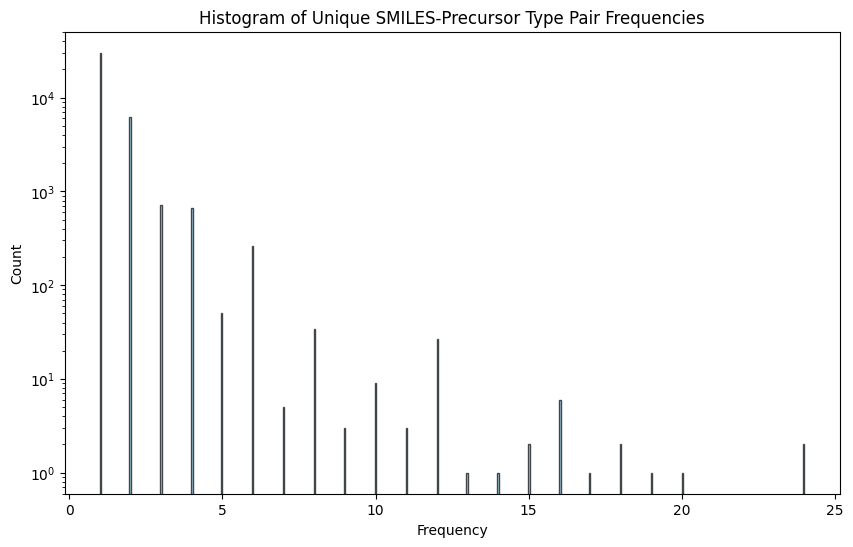

In [25]:
# Concatenate SMILES and precursor type columns from all datasets
smiles_prec_type = pd.concat([df[['smiles', 'prec_type']] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES-precursor type pair
smiles_prec_type_frequency = smiles_prec_type.value_counts().reset_index(name='count')

# Plot a histogram of the frequencies
plt.figure(figsize=(10, 6))
plt.hist(smiles_prec_type_frequency['count'], bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Unique SMILES-Precursor Type Pair Frequencies')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()

In [26]:
# Merge smiles_prec_type_frequency into smarts_train_df
smarts_train_df = smarts_train_df.merge(smiles_prec_type_frequency, on=['smiles', 'prec_type'], how='left')

# Display the updated DataFrame
smarts_train_df.head()

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count
0,9,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*C(O)c1ccc(OC)cc1,137.060255,C8H9*O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(1, 137.06080627441406, [[137.0595703125, 0.1...",2
1,13,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*C(C)C(O)c1ccc(OC)cc1,165.091555,C10H13*O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-1, 163.07644653320312, [[163.07501220703125...",2
2,15,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*OC(C)C(O)c1ccc(OC)cc1,181.086469,C10H13*O3,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-1, 179.0713653564453, [[179.07040405273438,...",2
3,16,[#6:1]1(-[#8:2]-[#6:3](-[#6:4]-[#8:5])-[#6:6](...,*C1OC(CO)C(O)C(O)C1O,163.060648,C6H11*O5,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-3, 159.0299072265625, [[159.02874755859375,...",3
4,30,[#8:1](-[#6:2]1:[#6:3]:[#6:4]:[#6:5](-[#6:6](-...,*Oc1ccc(C(*)O)cc1,122.036779,C7H6*2O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(0, 121.02950286865234, [[121.028076171875, 0...",2


In [27]:
# Count the number of '*' in each SMILES and add it as a new column 'break'
smarts_train_df['break'] = smarts_train_df['smiles'].apply(lambda x: x.count('*'))

# Display the updated DataFrame
smarts_train_df.head()

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count,break
0,9,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*C(O)c1ccc(OC)cc1,137.060255,C8H9*O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(1, 137.06080627441406, [[137.0595703125, 0.1...",2,1
1,13,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*C(C)C(O)c1ccc(OC)cc1,165.091555,C10H13*O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-1, 163.07644653320312, [[163.07501220703125...",2,1
2,15,[#6:1]-[#8:2]-[#6:3]1:[#6:4]:[#6:5]:[#6:6](-[#...,*OC(C)C(O)c1ccc(OC)cc1,181.086469,C10H13*O3,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-1, 179.0713653564453, [[179.07040405273438,...",2,1
3,16,[#6:1]1(-[#8:2]-[#6:3](-[#6:4]-[#8:5])-[#6:6](...,*C1OC(CO)C(O)C(O)C1O,163.060648,C6H11*O5,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(-3, 159.0299072265625, [[159.02874755859375,...",3,1
4,30,[#8:1](-[#6:2]1:[#6:3]:[#6:4]:[#6:5](-[#6:6](-...,*Oc1ccc(C(*)O)cc1,122.036779,C7H6*2O2,[M-H]-,COc1ccc(C(O)C(C)OC2OC(CO)C(O)C(O)C2O)cc1,JYWSARFDLXXOHT-UHFFFAOYSA-N,"[(0, 121.02950286865234, [[121.028076171875, 0...",2,2


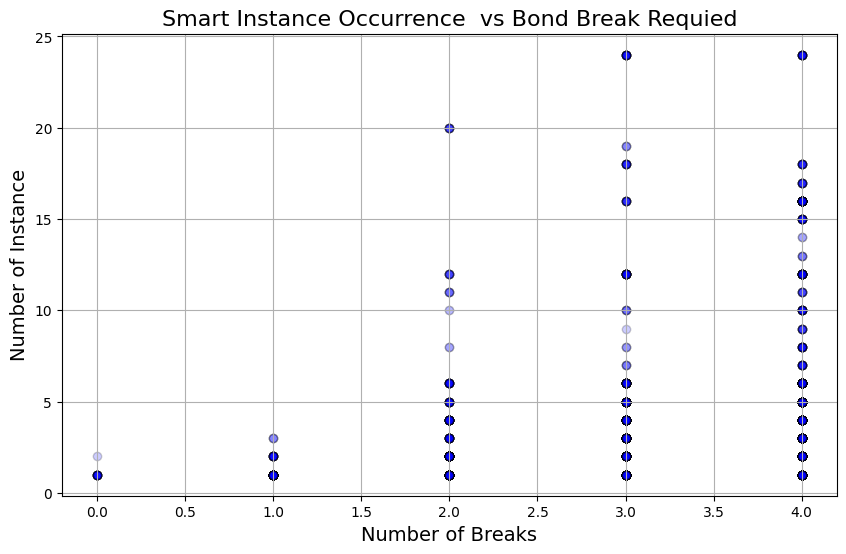

In [28]:
plt.figure(figsize=(10, 6))

# Scatter plot for count vs break
plt.scatter(smarts_train_df['break'], smarts_train_df['count'], alpha=0.1, color='blue', edgecolor='black')

# Add labels and title
plt.title('Smart Instance Occurrence  vs Bond Break Requied', fontsize=16)
plt.xlabel('Number of Breaks', fontsize=14)
plt.ylabel('Number of Instance', fontsize=14)

# Show the plot
plt.grid(True)
plt.show()

In [29]:
inchikey_prec_example_df = smarts_train_df[(smarts_train_df['mol_inchikey'] == 'AAAQFGUYHFJNHI-UHFFFAOYSA-N') \
                                           & (smarts_train_df['prec_type'] == '[M+H]+')]
inchikey_prec_example_df

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count,break


In [30]:
# Count the frequency of each unique molecular weight (mw)
mw_frequency = inchikey_prec_example_df['mw'].value_counts()

# Display the result
mw_frequency

Series([], Name: count, dtype: int64)

In [31]:
# De-duplicate by 'smiles'
deduplicated_df = inchikey_prec_example_df.reset_index().drop_duplicates(subset='smiles')

# Count the frequency of each unique molecular weight (mw)
mw_frequency_deduplicated = deduplicated_df['mw'].value_counts()

# Display the result
mw_frequency_deduplicated

Series([], Name: count, dtype: int64)

/tmp/ipykernel_2566700/14306029.py:6: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')  # Use log scale for better visualization


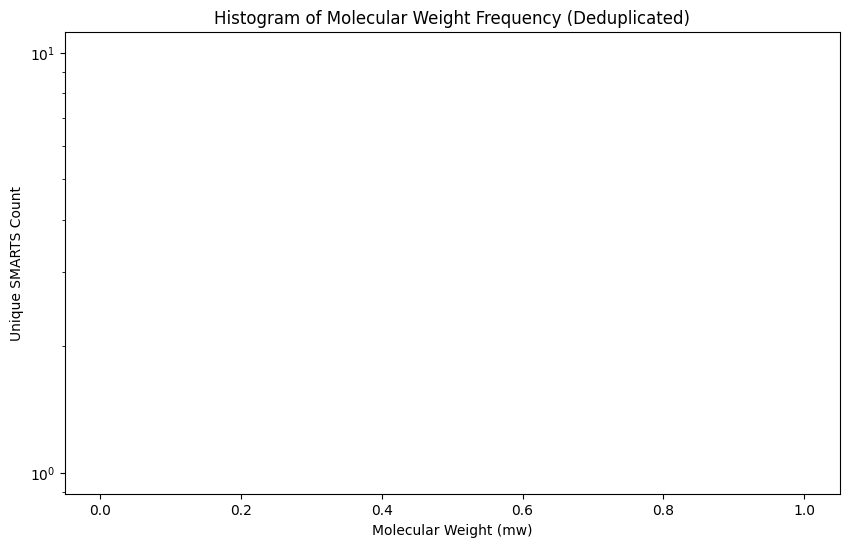

In [32]:
plt.figure(figsize=(10, 6))
plt.hist(mw_frequency_deduplicated.index, weights=mw_frequency_deduplicated.values, bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Molecular Weight Frequency (Deduplicated)')
plt.xlabel('Molecular Weight (mw)')
plt.ylabel('Unique SMARTS Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()